# NN_L8_diffusion_forward

**Lecture 8 of Neural Networks and Deep Learning (NN). Forward diffusion process applied to the last euro-area AAA yield curve of the sample: the curve at noise steps 0, 20, 60, 120 and 199.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_diffusion_forward/NN_L8_diffusion_forward.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$\mathbf x_t=\sqrt{\bar\alpha_t}\mathbf x_0+\sqrt{1-\bar\alpha_t}\boldsymbol\varepsilon$, linear $\beta_t$ from $10^{-4}$ to 0.02, $T=200$ (standardised maturities).

daily curves = 5664   [yc.n_days]
noise steps = 200   [yc.T]


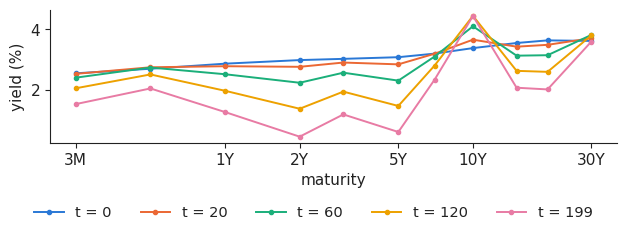

In [3]:
yc = pd.read_csv(DATA + 'ecb_yield_curve_daily.csv', parse_dates=['date']).set_index('date')
end = (yc.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
MAT = ['y_3M', 'y_6M', 'y_1Y', 'y_2Y', 'y_3Y', 'y_5Y', 'y_7Y', 'y_10Y', 'y_15Y', 'y_20Y', 'y_30Y']
yc = yc.loc[:end].dropna()
Y = yc[MAT].values
y10, slope = Y[:, 7], Y[:, 7] - Y[:, 0]
ym, ys = Y.mean(0), Y.std(0)
T = 200
beta = np.linspace(1e-4, 0.02, T)
abar = np.cumprod(1 - beta)
show('yc.n_days', 'daily curves', len(Y))
show('yc.T', 'noise steps', T)
x0 = (Y[-1] - ym) / ys
eps = np.random.default_rng(7).standard_normal(11)
mat = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30]
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for t, c in zip([0, 20, 60, 120, 199], SERIES):
    xt = np.sqrt(abar[t]) * x0 + np.sqrt(1 - abar[t]) * eps
    ax.plot(mat, xt * ys + ym, 'o-', ms=3, color=c, label=f't = {t}')
ax.set_xscale('log'); ax.set_xticks([0.25, 1, 2, 5, 10, 30]); ax.set_xticklabels(['3M', '1Y', '2Y', '5Y', '10Y', '30Y']); ax.minorticks_off()
ax.set_xlabel('maturity'); ax.set_ylabel('yield (%)')
legend_bottom(fig, ncol=5)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('diffusion_forward.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()